# Overview

This notebook evaluates annual TXx at each NClimGrid grid cell using the GLOST time series and three statistical tests:

**Durbin–Watson:** Checks whether residuals from the TXx–GLOST regression show first-order autocorrelation. Values near 2 suggest little autocorrelation.

**Augmented Dickey–Fuller (ADF):** Tests for a unit root. A p-value below 0.05 is evidence against a unit root and is consistent with stationarity.

**Mann–Kendall:** Tests for a monotonic trend in TXx. The p-value indicates trend significance; Kendall’s tau gives its direction and strength.


In [26]:
import os

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cartopy
import cartopy.crs as ccrs

from copy import copy

import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.stattools import adfuller
import pymannkendall as mk

import warnings
warnings.filterwarnings('ignore')

from matplotlib import colors


# Read TXx

In [6]:
yearb=1952
yeare=2025
rollingwindow=1
ifile=f'/Users/gahe5417/data/NClimGrid/AnnualMaximumDailyTmax.ncei_5km.{rollingwindow}drollingmean.nc'

dso = xr.open_dataset(ifile)
dso = dso.drop_vars('TXx_day')

dso = dso.sel(time=slice(f'{yearb-1}-01-01',f'{yeare}-02-01'))
dso = dso.sortby('lat')

units = 'K'

# degree C to Farenheit\n",
dso['TXx'] = (dso['TXx'] ) * 9/5 + 32 
units = f'$\degree$ F'

In [7]:

ds = dso
Tlon = ds.lon.data
Tlat = ds.lat.data

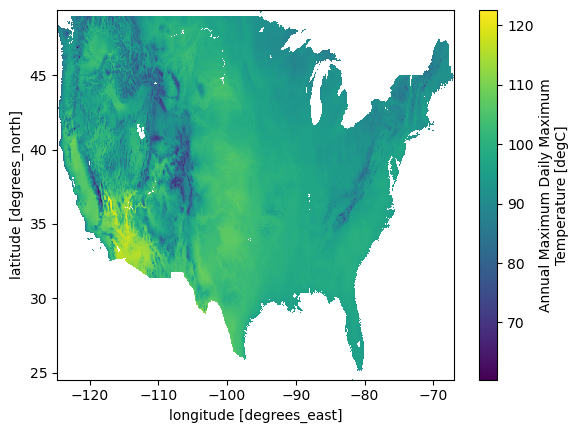

In [8]:
ds['TXx'].mean('time').plot()

# Read GLOST forcing

In [13]:
fileGLOST = '~/data/AFI/annual_LOESS_NOAA_GLOST_anomaly_1850_2025.nc'
ds_glost = xr.open_dataset(fileGLOST)
glost = ds_glost['GLOST'].sel(time=dso.time)

# Grid-Cell Statistical Diagnostics for TXx 

In [ ]:
# Initialize diagnostic fields
dw = xr.zeros_like(ds['TXx'].mean('time'))*np.nan
adf = xr.zeros_like(ds['TXx'].mean('time'))*np.nan
mkp = xr.zeros_like(ds['TXx'].mean('time'))*np.nan
mkt = xr.zeros_like(ds['TXx'].mean('time'))*np.nan

mask=xr.where(np.isnan(ds['TXx'].mean('time'))==False,1,0)

idlat,idlon=np.where(mask==1)

# Prepare your data (Example: y depends on x)
x = ds['time'].data 
x = glost.data

for ij in range(0,len(idlon)):
  jj=idlat[ij]
  ii=idlon[ij]
  ilon=Tlon[ii]
  ilat=Tlat[jj]

  # Extract grid-cell series
  dsij=ds.sel(lon=ilon,lat=ilat)

  y = dsij['TXx'].data

  # Fit TXx–GLOST regression
  x = sm.add_constant(x) # Add an intercept
  model = sm.OLS(y, x).fit()

  # Calculate Durbin–Watson statistic
  dw_statistic = durbin_watson(model.resid)
  # Test TXx stationarity
  result_adf = adfuller(y)
  # Test TXx trend
  result_mk = mk.original_test(y)

  dw.loc[{'lat':ilat,'lon':ilon}] = dw_statistic
  adf.loc[{'lat':ilat,'lon':ilon}] = result_adf[1]
  mkp.loc[{'lat':ilat,'lon':ilon}] = result_mk.p
  mkt.loc[{'lat':ilat,'lon':ilon}] = result_mk.Tau

# Map the results
Plot each stored diagnostic to examine its spatial pattern across the valid grid cells.

In [ ]:
state_borders =\
cartopy.feature.NaturalEarthFeature(category='cultural',\
        name='admin_1_states_provinces_lakes', scale='50m', facecolor='none')

## Build colorbar
from matplotlib import cm
clevsa=np.arange(0.06,1.01,0.01)
clevsb=np.arange(0,0.051,0.001)
clevs_pv=np.concatenate((clevsb,clevsa))
cmap = cm.get_cmap('Purples',len(clevsa)+20)
cmaplist = [cmap(i) for i in range(20,cmap.N)]
cmap2 = cm.get_cmap('YlGn_r', len(clevsb)+5)
cmaplist2 = [cmap2(i) for i in range(0,cmap2.N-5)]

pvalue_cmap = colors.LinearSegmentedColormap.from_list('Custom cmap',\
                cmaplist2+cmaplist, len(cmaplist2)+len(cmaplist))

Text(0.5, 1.0, 'Durbin-Watson statistic')

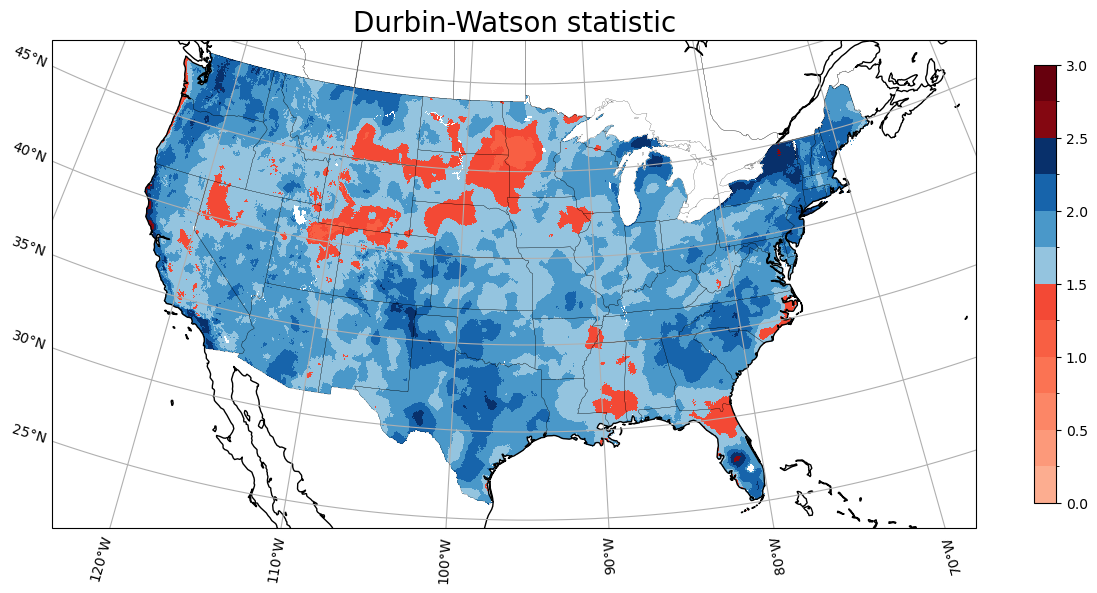

In [ ]:
clevs = np.arange(0,3.25,0.25)
cmap_r=plt.get_cmap('Reds',len(clevs)+5)
cmap_b=plt.get_cmap('Blues',4+2)
ccolors = [cmap_r(i) for i in range(5,cmap_r.N)]
ccolors[np.where(clevs==1.5)[0].item():np.where(clevs==2.5)[0].item()+1]=[cmap_b(i) for i in range(2,cmap_b.N)]
cmap= colors.LinearSegmentedColormap.from_list('Custom cmap',\
                ccolors, len(ccolors))
proj=ccrs.LambertConformal(265,25)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,10),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.15, right=0.95)

clevs = np.arange(0,3.25,0.25)
cc=dw.plot.pcolormesh(ax=ax,cmap=cmap,levels=clevs,transform=ccrs.PlateCarree(),\
                        add_colorbar=True,cbar_kwargs={'shrink':0.6,'label':''})
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()
#cbar=fig.colorbar(cc)
#cbar.ax.tick_params(labelsize=14)  
#cbar.set_label(label='',fontsize=16)  
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
plt.title(f'Durbin-Watson statistic',fontsize=20)

*caption: Spatial distribution of the Durbin–Watson statistic calculated from residuals of the regression of annual TXx on the GLOST time series at each NClimGrid grid cell. Values near 2 indicate little evidence of first-order autocorrelation in the residuals; values below 2 suggest positive autocorrelation, and values above 2 suggest negative autocorrelation. Blue shading highlights values from 1.5 to 2.5, while red shading marks values outside that range. Color intervals are 0.25.*

Text(0.5, 1.0, 'ADF pvalue')

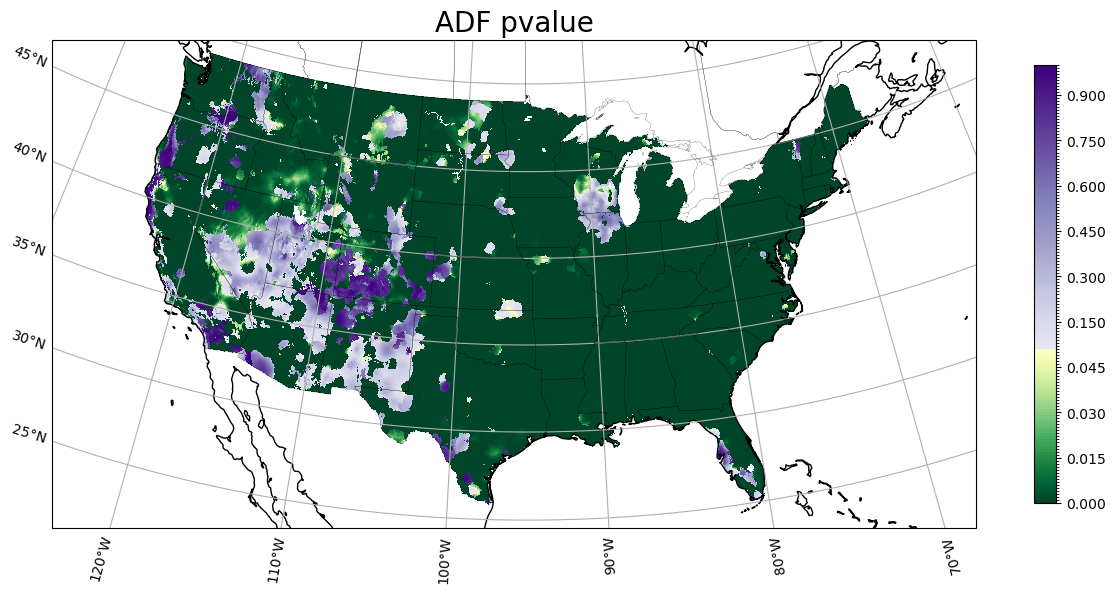

In [30]:
proj=ccrs.LambertConformal(265,25)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,10),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.15, right=0.95)

clevs = np.arange(0,3.25,0.25)
cc=adf.plot.pcolormesh(ax=ax,cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),\
    add_colorbar=True,cbar_kwargs={'shrink':0.6,'label':''})
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
plt.title(f'ADF pvalue',fontsize=20)

*Augmented Dickey–Fuller (ADF) test: Spatial distribution of the ADF test p-values for the annual TXx series at each NClimGrid grid cell. The null hypothesis is that the series has a unit root, indicating nonstationarity. At the 0.05 significance level, p-values below 0.05 provide evidence to reject the unit-root null, which is evidence that the series is stationary around a constant. Larger p-values mean there is insufficient evidence to reject the null, consistent with nonstationarity, but do not prove that the series is nonstationary.*

Text(0.5, 1.0, 'Mann-Kendall Trend Test pvalue')

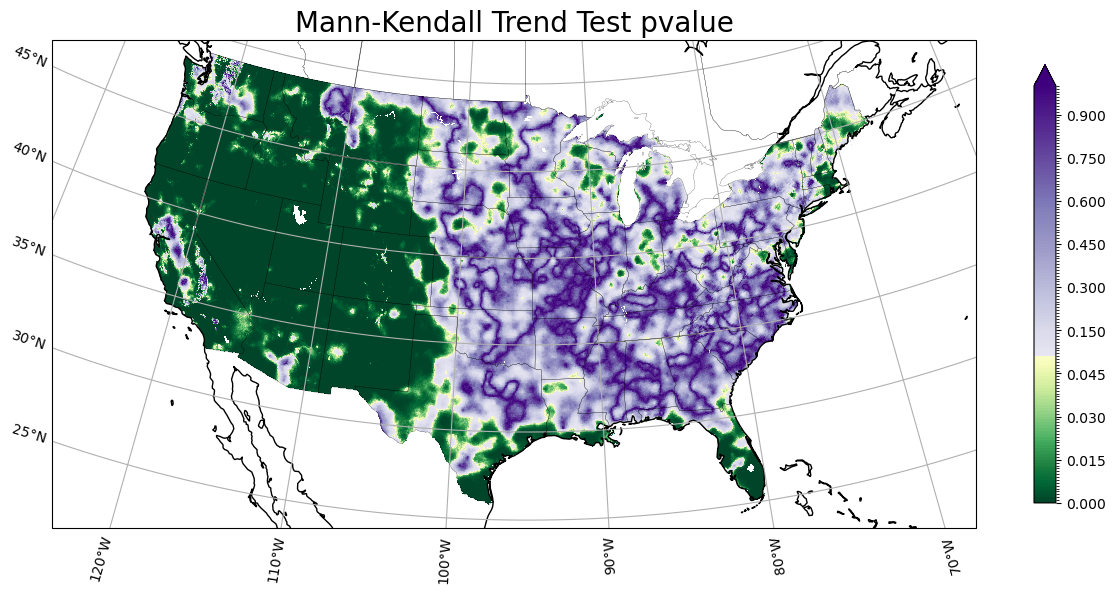

In [32]:
proj=ccrs.LambertConformal(265,25)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,10),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.15, right=0.95)

clevs = np.arange(0,3.25,0.25)
cc=mkp.plot.pcolormesh(ax=ax,cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),\
    add_colorbar=True,cbar_kwargs={'shrink':0.6,'label':''} )
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()

gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
plt.title(f'Mann-Kendall Trend Test pvalue',fontsize=20)

*Mann–Kendall test p-values: Spatial distribution of p-values from the Mann–Kendall test applied to annual TXx at each grid cell. Values below 0.05 indicate statistically significant evidence of a monotonic trend. See Kendall’s τ for trend direction.*

Text(0.5, 1.0, 'Mann-Kendall Trend Test Tau')

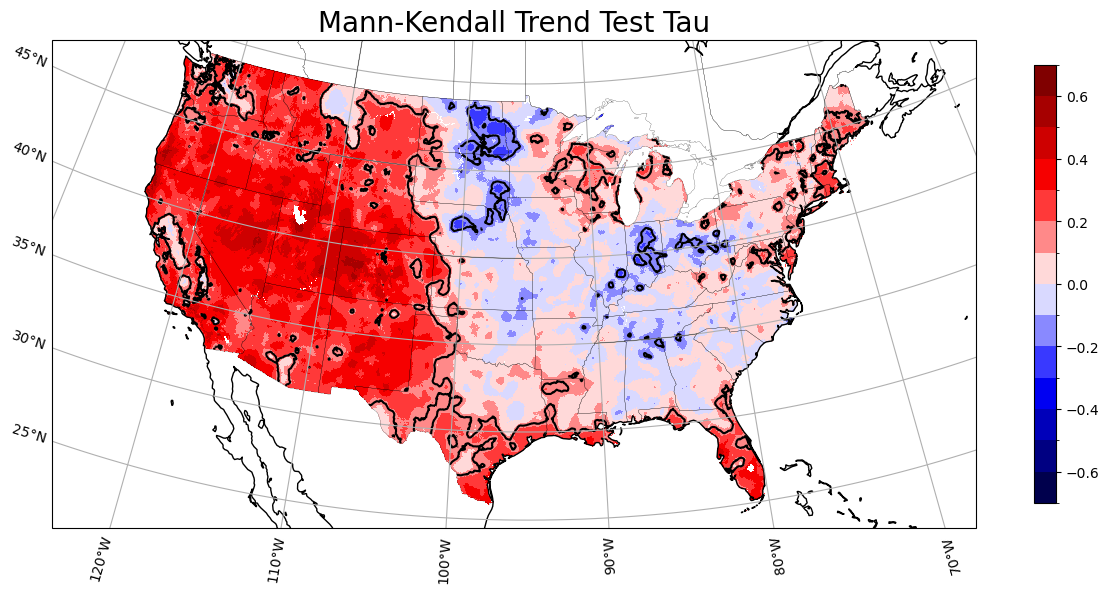

In [34]:
proj=ccrs.LambertConformal(265,25)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,10),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.15, right=0.95)

clevs = np.arange(0,3.25,0.25)
cc=mkt.plot.pcolormesh(ax=ax,cmap='seismic',levels=np.arange(-0.7,0.8,0.1),transform=ccrs.PlateCarree(),\
    add_colorbar=True,cbar_kwargs={'shrink':0.6,'label':''})
mkp.plot.contour(ax=ax,colors='k',levels=[0.05],transform=ccrs.PlateCarree())
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()

gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
plt.title(f'Mann-Kendall Trend Test Tau',fontsize=20)

*Mann–Kendall trend statistic (Kendall’s τ): Map of Kendall’s τ for annual TXx at each grid cell. Positive values indicate an increasing monotonic trend; negative values indicate a decreasing trend. Black contours outline regions where the Mann–Kendall test p-value is 0.05, separating areas with statistically significant trends (p < 0.05) from those without. Use the p-value map to assess significance and τ to identify trend direction and strength.*